<a href="https://colab.research.google.com/github/Pranov1984/PEFT-BERT-IMDB-Sentiment-Analysis/blob/main/QLoRA_BERT_Fine_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><font size=6>Parameter-Efficient Fine-Tuning of BERT for Text Classification using QLoRA</font></h1></center>
<center><h3>LLM Fine-Tuning with PEFT</h3></center>

## Problem Statement

### Business Context

Online movie platforms such as IMDb collect thousands of user reviews every day. Knowing whether a review is positive or negative helps a platform understand how audiences received a film, bring useful reviews to the top and spot problems early. Reading every review by hand is not practical, so platforms need an automated way to classify the sentiment of text.

Large language models like BERT are very good at this kind of text classification. The difficulty is the cost of adapting them to a task: fine-tuning all the weights of a model needs a lot of GPU memory and time, which is a problem for small teams or for anyone working on a personal machine or a free Colab GPU.

### Problem Definition

Full fine-tuning of BERT updates all of its ~110 million parameters, and the GPU has to hold the weights, the gradients and the optimizer states for every one of them. This cost grows quickly as models get bigger.

Parameter-efficient fine-tuning (PEFT) methods avoid this by training only a small set of new weights while the original model stays frozen. **LoRA** adds small low-rank adapter matrices to selected layers of the model. **QLoRA** goes one step further and stores the frozen model in 4-bit precision (quantization), which reduces the memory needed even more.

This case study applies QLoRA to a BERT model for movie-review sentiment classification. We check how much memory and how many trainable parameters it saves compared with full fine-tuning, and what it costs in accuracy.

## Methodology

**Data Preparation and Tokenization:** We load the IMDB sentiment dataset from the Hugging Face Hub, clean the text, split the training data into training and validation sets and tokenize the reviews with the BERT tokenizer. The separate test set is kept aside for the final evaluation.

**Model Setup with Quantization:** We load `bert-base-uncased` in 4-bit precision using `bitsandbytes` and attach LoRA adapters to it (QLoRA).

**Training:** We fine-tune the model with the Hugging Face `Trainer`. Only the adapters and the classification layer are trained. The training is logged to Weights & Biases.

**Evaluation:** We evaluate the model on the validation and test sets using accuracy, F1-score, a confusion matrix and a classification report, and compare it with the model before fine-tuning.

**Analysis and Interpretation:** We compare QLoRA with full fine-tuning in terms of trainable parameters, GPU memory, checkpoint size, training time and accuracy.

## Objective

Fine-tune a BERT model with QLoRA on a binary text classification dataset and evaluate its performance on the test set. Then compare it with full fine-tuning in terms of accuracy and memory / parameter efficiency.

### Before running the notebook

1. `Runtime → Change runtime type → T4 GPU`
2. Add these three secrets in Colab (key icon in the left sidebar) and switch on *Notebook access* for each: `WANDB_API_KEY`, `HF_API_KEY` and `CLAUDE_API_KEY`
3. Run the cells from top to bottom. The full fine-tuning comparison frees the GPU memory, so later cells depend on the earlier ones.

## Importing the necessary libraries

In [ ]:
# installing the libraries to load the models, adapters, 4-bit quantization, experiment tracking and the Claude API
!pip install transformers peft bitsandbytes accelerate datasets wandb anthropic -U -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
# Import necessary libraries for data manipulation and analysis
import os
import gc
import re
import numpy as np
import pandas as pd

# Import visualization libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Import modules from scikit-learn for machine learning tasks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, classification_report

# Import PyTorch and the Hugging Face libraries
import torch
import bitsandbytes as bnb
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, BitsAndBytesConfig, TrainingArguments, Trainer, set_seed
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training, PeftModel

# Import the tools for the Hugging Face Hub and Weights & Biases
from huggingface_hub import login
import wandb

In [ ]:
# saving the versions of the libraries used in this notebook
!pip freeze > requirements.txt

### Setting the parameters

In [ ]:
# main parameters of the project, all in one place
seed = 42
device = 'cuda'
model_name = 'bert-base-uncased'
dataset_name = 'dipanjanS/imdb_sentiment_finetune_dataset20k'
max_length = 256        # maximum number of tokens kept for each review
batch_size = 16
num_epochs = 2
lr = 2e-4               # learning rate for QLoRA (LoRA works well with a higher learning rate)
lr_full = 2e-5          # learning rate for full fine-tuning (used only for the comparison at the end)
lora_r = 16             # rank of the LoRA adapters
lora_alpha = 32         # scaling factor of the LoRA adapters
lora_dropout = 0.1      # dropout inside the LoRA adapters
quick_test = False      # set to True for a fast trial run (1,000 training and 300 test reviews)

# Set the seed for the random number generators to ensure reproducibility
set_seed(seed)

### Reading the API keys from the Colab secrets and logging in

In [ ]:
# reading the API keys saved as Colab secrets
from google.colab import userdata
hf_token = userdata.get('HF_API_KEY')
wandb_key = userdata.get('WANDB_API_KEY')

In [ ]:
# logging in to the Hugging Face Hub and to Weights & Biases
login(token=hf_token.strip())
wandb.login(key=wandb_key.strip())

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.forge.coreweave.com.
wandb: No netrc file found, creating one.
wandb: Appending key for api.forge.coreweave.com to your netrc file: /root/.netrc
wandb: Currently logged in as: pranovmishra (pranovmishra-jpmorgan-chase-co-) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

### Checking the GPU

In [ ]:
!nvidia-smi

Tue Nov 10 18:46:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Loading the dataset

The dataset has a `train` file and a `test` file on the Hugging Face Hub. `load_dataset` downloads both of them, and we are already logged in with our Hugging Face token.

In [ ]:
# loading the dataset from the Hugging Face Hub
dataset = load_dataset(dataset_name)
dataset

README.md:   0%|          | 0.00/534 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.89MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.70MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.61MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review', 'sentiment'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['review', 'sentiment'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['review', 'sentiment'],
        num_rows: 10000
    })
})

- If you would rather read the downloaded parquet files from Google Drive, mount the drive and use `pd.read_parquet('/content/drive/MyDrive/train-00000-of-00001.parquet')` and `pd.read_parquet('/content/drive/MyDrive/test-00000-of-00001.parquet')` in the next cell instead.

In [ ]:
# converting the train and test splits into pandas dataframes
data_training = dataset['train'].to_pandas()
data_testing = dataset['test'].to_pandas()

In [ ]:
# optional: using a smaller sample for a fast trial run
if quick_test:
    data_training = data_training.sample(n=1000, random_state=seed).reset_index(drop=True)
    data_testing = data_testing.sample(n=min(300, len(data_testing)), random_state=seed).reset_index(drop=True)

## Data Overview

### Checking the first five rows of the data

In [ ]:
# Print first 5 rows of data
data_training.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


### Checking the shape of the dataset

In [ ]:
# print shape of data
print('Training data:', data_training.shape)
print('Test data:', data_testing.shape)

Training data: (8000, 2)
Test data: (10000, 2)


- Each row is one movie review (`review`) with its sentiment label (`sentiment`)

### Checking for missing values

In [ ]:
# Check for missing values
print(data_training.isnull().sum())
print(data_testing.isnull().sum())

review       0
sentiment    0
dtype: int64
review       0
sentiment    0
dtype: int64


- There are no missing values in the data

### Checking the target classes

In [ ]:
# number of positive (1) and negative (0) reviews in the training and test data
pd.DataFrame({'train': data_training['sentiment'].value_counts(), 'test': data_testing['sentiment'].value_counts()})

,train,test
sentiment,,
0,3997,5125
1,4003,4875


- The two classes are balanced, so accuracy is a fair metric to use
- `sentiment` is already numeric: 1 = positive and 0 = negative

### Checking the length of the reviews

In [ ]:
# number of words in each training review
data_training['review'].str.split().str.len().describe()

,review
count,8000.000000
mean,231.878625
std,171.849457
min,14.000000
25%,127.000000
50%,173.000000
75%,283.250000
max,1830.000000


- The reviews vary a lot in length, so we will cut them at `max_length` tokens during tokenization

### Cleaning the text

The reviews contain HTML line breaks (`<br />`). They carry no sentiment, but the tokenizer would split each one into several tokens and waste part of the `max_length` budget. We replace them with a space.

In [ ]:
# number of training reviews that contain HTML line breaks
data_training['review'].str.contains('<br />').sum()

np.int64(4688)

In [ ]:
# function to remove the HTML line breaks and the extra spaces from a review
def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text)    # replace <br /> tags with a space
    return ' '.join(text.split())             # remove the extra spaces

# applying the function to the training and test reviews
data_training['review'] = data_training['review'].apply(clean_text)
data_testing['review'] = data_testing['review'].apply(clean_text)

In [ ]:
# looking at a cleaned review
data_training['review'][0][:300]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this"

### Checking for reviews present in both the training and the test data

In [ ]:
# number of identical reviews present in both datasets
len(set(data_training['review']) & set(data_testing['review']))

28

- A test review that also appears in the training data would make the test result look better than it is, so this number should be zero or very small

#### **Splitting the dataset**

In [ ]:
# Creating dependent and independent variables
X = data_training['review']
y = data_training['sentiment']

In [ ]:
# Split the training data into training (80%) and validation (20%) sets, keeping the class proportions the same
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [ ]:
print(X_train.shape, X_valid.shape)

(6400,) (1600,)


In [ ]:
print(y_train.shape, y_valid.shape)

(6400,) (1600,)


In [ ]:
# The separate test file is used only for the final testing
X_test = data_testing['review']
y_test = data_testing['sentiment']

#### **Label Encoding**

In [ ]:
# Label Encoding
encoder = LabelEncoder()

# fitting the encoder to the training labels
y_train_enc = encoder.fit_transform(y_train)

# applying the encoder mapping from training labels to validation and test labels
y_valid_enc = encoder.transform(y_valid)
y_test_enc = encoder.transform(y_test)

- The labels are already 0 and 1, so the encoder keeps them as they are

In [ ]:
# names of the classes, in the order of the encoded labels (0 = negative, 1 = positive)
assert list(encoder.classes_) == [0, 1]
class_names = ['negative', 'positive']
id2label = {0: 'negative', 1: 'positive'}
label2id = {'negative': 0, 'positive': 1}
num_classes = len(class_names)

#### **Tokenization**

In [ ]:
# loading and creating an instance of the BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, do_lower_case=True)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

- `do_lower_case` argument converts the input to lowercase when it is set to *True*

In [ ]:
# checking how many training reviews are longer than max_length tokens (these will be cut)
lengths = [len(ids) for ids in tokenizer(X_train.values.tolist()[:2000], truncation=False)['input_ids']]
print(f'{np.mean(np.array(lengths) > max_length):.0%} of the reviews are longer than {max_length} tokens')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (568 > 512). Running this sequence through the model will result in indexing errors


40% of the reviews are longer than 256 tokens


In [ ]:
X_train_tokenized = tokenizer(
    X_train.values.tolist(),      # passing the data as a list to the tokenizer
    max_length=max_length,        # specifies the maximum length of the tokenized data
    padding='max_length',         # padding the data to the specified maximum length
    truncation=True,              # truncating the input if it is longer than the specified maximum length
    return_attention_mask=True,   # specifying to return attention masks
    return_token_type_ids=False,  # not needed, every input is a single review
)

In [ ]:
X_valid_tokenized = tokenizer(
    X_valid.values.tolist(),
    max_length=max_length,
    padding='max_length',
    truncation=True,
    return_attention_mask=True,
    return_token_type_ids=False,
)

In [ ]:
X_test_tokenized = tokenizer(
    X_test.values.tolist(),
    max_length=max_length,
    padding='max_length',
    truncation=True,
    return_attention_mask=True,
    return_token_type_ids=False,
)

#### **Creating Hugging Face datasets**

The `Trainer` works with Hugging Face `Dataset` objects. We can create them in the following steps.

1. Take the tokenized input as a dictionary
2. Add the encoded target labels to the dictionary under the name `labels`
3. Convert the dictionary into a `Dataset`

In [ ]:
# converting the tokenized training data and its labels into a Hugging Face dataset
train_ds = Dataset.from_dict({**X_train_tokenized, 'labels': y_train_enc.tolist()})

# converting the tokenized validation data and its labels into a Hugging Face dataset
valid_ds = Dataset.from_dict({**X_valid_tokenized, 'labels': y_valid_enc.tolist()})

# converting the tokenized test data and its labels into a Hugging Face dataset
test_ds = Dataset.from_dict({**X_test_tokenized, 'labels': y_test_enc.tolist()})

In [ ]:
print(train_ds)

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 6400
})


## Model Building with QLoRA

### Loading the model in 4-bit

QLoRA keeps the pre-trained BERT weights frozen and stores them in 4-bit precision (quantization). Small LoRA adapters are added on top, and only the adapters and the new classification layer are trained. The 4-bit settings are given in a `BitsAndBytesConfig`.

In [ ]:
# configuring the 4-bit quantization
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,                       # store the frozen weights in 4 bits instead of 32
    bnb_4bit_quant_type='nf4',               # NormalFloat4, a 4-bit data type designed for neural network weights
    bnb_4bit_use_double_quant=True,          # also quantize the quantization constants to save a little more memory
    bnb_4bit_compute_dtype=torch.float16,    # the calculations are done in 16-bit after the weights are decompressed
    llm_int8_skip_modules=['classifier'],    # keep the new classification layer in full precision
)

- `load_in_4bit` loads the weights of the model in 4-bit precision
- `nf4` is the 4-bit data type recommended in the QLoRA paper
- `bnb_4bit_compute_dtype` is the precision used for the calculations, `float16` works on the free Colab GPU

In [ ]:
# Model initialization using BERT for sequence classification, loaded in 4-bit
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id,
    device_map={'': 0},      # place the model on the GPU
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


- The warning about newly initialized weights is expected, the classification layer has not been trained yet

In [ ]:
# checking that the linear layers are in 4-bit and how much GPU memory the weights of the model take
print(sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules()), 'linear layers are now in 4-bit')

qlora_model_size = model.get_memory_footprint() / 1024**2
print(f'Size of the 4-bit model: {qlora_model_size:.0f} MB')

73 linear layers are now in 4-bit
Size of the 4-bit model: 132 MB


In [ ]:
!nvidia-smi

Tue Nov 10 18:50:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P0             26W /   70W |     271MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Preparing the model for training

In [ ]:
# preparing the 4-bit model for training (keeps the small layers like LayerNorm in full precision)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)

### Adding the LoRA adapters

In [ ]:
# LoRA configuration
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,                    # sequence classification, also keeps the classification layer trainable
    r=lora_r,                                      # rank of the adapters
    lora_alpha=lora_alpha,                         # scaling factor of the adapters
    lora_dropout=lora_dropout,                     # dropout inside the adapters
    target_modules=['query', 'key', 'value'],      # layers of BERT that get an adapter (self-attention)
    bias='none',                                   # the bias terms are not trained
)

- `r` is the rank of the adapter matrices, a bigger value means more trainable parameters
- `lora_alpha` scales the output of the adapters
- `target_modules` are the layers of BERT that get an adapter, here the query, key and value layers of the self-attention

In [ ]:
# adding the adapters to the 4-bit model
model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

trainable params: 886,274 || all params: 110,370,052 || trainable%: 0.8030


In [ ]:
# saving the number of trainable and total parameters after applying QLoRA
qlora_trainable, qlora_total = model.get_nb_trainable_parameters()
print(f'Trainable parameters: {qlora_trainable:,} out of {qlora_total:,} ({qlora_trainable / qlora_total:.2%})')

Trainable parameters: 886,274 out of 110,370,052 (0.80%)


### Setting up the Trainer

In [ ]:
# function to calculate the metrics during the evaluation
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': accuracy_score(labels, preds), 'f1': f1_score(labels, preds, average='macro')}

In [ ]:
# starting a Weights & Biases run to log the training
wandb.init(project='bert_qlora_imdb', name='qlora_bert')

### **What does `wandb.init()` do?**

The `wandb.init()` function initializes a new run in **Weights & Biases (W&B)**. Here is what its parameters do:

* **`project='bert_qlora_imdb'`**: Groups all related runs under a single project dashboard called `bert_qlora_imdb` on your W&B account.
* **`name='qlora_bert'`**: Assigns a readable, custom name to this specific training run so you can easily identify and compare it against other runs (such as the full fine-tuning baseline) later.

In [ ]:
# setting the training arguments
training_args = TrainingArguments(
    output_dir='bert_qlora_outputs',
    num_train_epochs=num_epochs,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    learning_rate=lr,
    weight_decay=0.01,
    warmup_steps=50,
    eval_strategy='epoch',       # evaluate on the validation set after every epoch
    save_strategy='no',          # no large checkpoints, only the small adapter is saved later
    logging_steps=50,            # log the training loss every 50 steps
    fp16=True,                   # mixed precision training
    report_to='wandb',           # log the metrics to Weights & Biases
    run_name='qlora_bert',
    seed=seed,
)

- The loss and the accuracy on the validation set are calculated after every epoch and logged to Weights & Biases
- `fp16` trains in mixed precision, which is faster and uses less memory

In [ ]:
# creating the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    compute_metrics=compute_metrics,
)

### Checking the model on the test dataset before fine-tuning

In [ ]:
# predictions of the model on the test set before fine-tuning
preds_raw_test = trainer.predict(test_ds)
preds_test = np.argmax(preds_raw_test.predictions, axis=1)
actual_test = preds_raw_test.label_ids

In [ ]:
accuracy_before = accuracy_score(actual_test, preds_test)
print(accuracy_before)

0.4875


- The classification layer is still random before fine-tuning, so the accuracy should be close to 50%, which is the chance level for two balanced classes

### Predicting the sentiment of new reviews before fine-tuning

In [ ]:
# some new reviews to test the model on
sample_reviews = [
    'An absolute masterpiece. The acting was superb and the ending left me speechless.',
    'Two hours of my life I will never get back. Dull, predictable and badly acted.',
    'Not bad, but not great either. A few good scenes carried a weak script.',
]

In [ ]:
# function to predict the sentiment of new reviews
def predict_reviews(model, reviews):
    model.eval()
    inputs = tokenizer(reviews, max_length=max_length, padding=True, truncation=True, return_token_type_ids=False, return_tensors='pt').to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
    probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    for review, p in zip(reviews, probs):
        print(f'{class_names[p.argmax()]:<9} ({p.max():.2f}) | {review}')

In [ ]:
predict_reviews(model, sample_reviews)

positive  (0.63) | An absolute masterpiece. The acting was superb and the ending left me speechless.
positive  (0.63) | Two hours of my life I will never get back. Dull, predictable and badly acted.
positive  (0.60) | Not bad, but not great either. A few good scenes carried a weak script.


### Fine-tuning the model

In [ ]:
# resetting the GPU memory counter so that we measure the peak memory of this training run only
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

In [ ]:
# training the model
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.268709,0.250175,0.908750,0.908594
2,0.214305,0.236938,0.902500,0.902495


In [ ]:
# peak GPU memory and the time taken by the QLoRA training
qlora_peak_mem = torch.cuda.max_memory_allocated() / 1024**2
qlora_time = train_result.metrics['train_runtime'] / 60
print(f'Peak GPU memory during QLoRA training: {qlora_peak_mem:.0f} MB')
print(f'Training time: {qlora_time:.1f} minutes')

Peak GPU memory during QLoRA training: 1857 MB
Training time: 3.2 minutes


- The training loss, validation loss and accuracy of every epoch are shown in the table above and in the Weights & Biases dashboard
- Peak GPU memory is measured with `torch.cuda.max_memory_allocated`

### Evaluating the model on the validation set

In [ ]:
# predictions on the validation set
preds_raw_val = trainer.predict(valid_ds)
preds_val = np.argmax(preds_raw_val.predictions, axis=1)
actual_val = preds_raw_val.label_ids

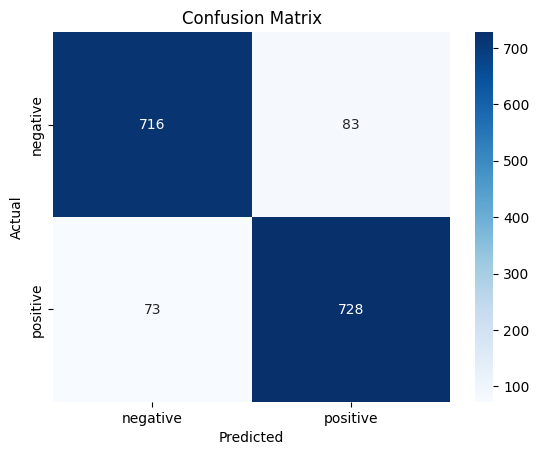

In [ ]:
# Creating confusion matrix
cnf_mt = confusion_matrix(actual_val, preds_val)

# Visualizing confusion matrix using a heatmap
sns.heatmap(cnf_mt, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Display classification report
print('Classification Report:')
print(classification_report(actual_val, preds_val, target_names=class_names))

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.90      0.90       799
    positive       0.90      0.91      0.90       801

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.90      1600
weighted avg       0.90      0.90      0.90      1600



In [ ]:
micro_f1_score_val = f1_score(actual_val, preds_val, average='micro')
print(micro_f1_score_val)

0.9025


- The model achieved 90,25% accuracy on the validation set

## Model Testing

In [ ]:
# predictions on the test set
preds_raw_test = trainer.predict(test_ds)
preds_test = np.argmax(preds_raw_test.predictions, axis=1)
actual_test = preds_raw_test.label_ids

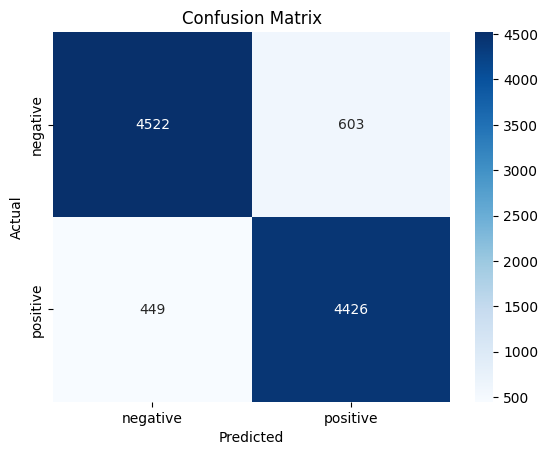

In [ ]:
cnf_mt = confusion_matrix(actual_test, preds_test)

sns.heatmap(cnf_mt, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
print('Classification Report:')
print(classification_report(actual_test, preds_test, target_names=class_names))

Classification Report:
              precision    recall  f1-score   support

    negative       0.91      0.88      0.90      5125
    positive       0.88      0.91      0.89      4875

    accuracy                           0.89     10000
   macro avg       0.89      0.90      0.89     10000
weighted avg       0.90      0.89      0.89     10000



In [ ]:
micro_f1_score = f1_score(actual_test, preds_test, average='micro')
print(micro_f1_score)

0.8948


In [ ]:
# saving the test results of QLoRA for the comparison at the end
qlora_test_acc = accuracy_score(actual_test, preds_test)
qlora_test_f1 = f1_score(actual_test, preds_test, average='macro')
print(f'Test accuracy before fine-tuning: {accuracy_before:.4f}')
print(f'Test accuracy after fine-tuning:  {qlora_test_acc:.4f}')

Test accuracy before fine-tuning: 0.4875
Test accuracy after fine-tuning:  0.8948


- The model achieved 89.48% accuracy on the test set, compared with about 50% before fine-tuning

In [ ]:
# logging the final test results to Weights & Biases and closing the run
wandb.log({'test_accuracy': qlora_test_acc, 'test_f1': qlora_test_f1, 'peak_gpu_memory_mb': qlora_peak_mem, 'trainable_parameters': qlora_trainable})
wandb.finish()

eval/accuracy,█▁
eval/f1,█▁
eval/loss,█▁
eval/model_preparation_time,▁▁
eval/runtime,▁▁
eval/samples_per_second,█▁
eval/steps_per_second,▁▁
peak_gpu_memory_mb,▁
test/accuracy,▁██
test/f1,▁██
+13,...


### Predicting the sentiment of new reviews after fine-tuning

In [ ]:
predict_reviews(model, sample_reviews)

positive  (1.00) | An absolute masterpiece. The acting was superb and the ending left me speechless.
negative  (0.92) | Two hours of my life I will never get back. Dull, predictable and badly acted.
negative  (0.98) | Not bad, but not great either. A few good scenes carried a weak script.


## Saving the adapter and optionally pushing it to the Hub

Only the small LoRA adapter (and the trained classification layer) needs to be saved, the 4-bit base model can be downloaded again from the Hub.

- Option 1: save the adapter locally
- Option 2: push the adapter to the Hugging Face Hub (needs a Hugging Face token with write access)

In [ ]:
# saving the adapter locally
peft_model_id = 'bert_qlora_imdb_adapter'
model.save_pretrained(peft_model_id)

In [ ]:
# optionally pushing the adapter to the Hugging Face Hub, change push_to_hub to True to upload
push_to_hub = False
if push_to_hub:
    model.push_to_hub('bert-qlora-imdb', private=True, token=hf_token)

### Check the size of the checkpoint

In [ ]:
# size of the saved adapter
adapter_size_mb = sum(os.path.getsize(os.path.join(peft_model_id, f)) for f in os.listdir(peft_model_id) if f.startswith('adapter_model')) / 1024**2
print(f'Size of the saved adapter: {adapter_size_mb:.2f} MB')

Size of the saved adapter: 3.39 MB


## Comparison with Full Fine-Tuning

To see how much QLoRA saves, we also fine-tune BERT in the usual way, where all the weights are trained in full precision. We use the same data, batch size and number of epochs, and measure the same things: trainable parameters, GPU memory, checkpoint size, training time and test accuracy.

### Freeing the GPU memory

In [ ]:
# removing the QLoRA model from the GPU so that it does not affect the memory measured for full fine-tuning
del model, trainer
gc.collect()
torch.cuda.empty_cache()

### Loading the full-precision model

In [ ]:
# loading a normal full-precision BERT model on the GPU
full_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id,
).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# in full fine-tuning all the parameters are trainable
full_trainable = sum(p.numel() for p in full_model.parameters() if p.requires_grad)
full_total = sum(p.numel() for p in full_model.parameters())
full_model_size = full_model.get_memory_footprint() / 1024**2

print(f'Trainable parameters: {full_trainable:,} out of {full_total:,}')
print(f'Size of the full-precision model: {full_model_size:.0f} MB')

Trainable parameters: 109,483,778 out of 109,483,778
Size of the full-precision model: 418 MB


### Fine-tuning all the parameters

In [ ]:
# starting a new Weights & Biases run
wandb.init(project='bert_qlora_imdb', name='full_finetune_bert')

In [ ]:
# training arguments for full fine-tuning, only the learning rate and the names are different
training_args_full = TrainingArguments(
    output_dir='bert_full_outputs',
    num_train_epochs=num_epochs,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    learning_rate=lr_full,
    weight_decay=0.01,
    warmup_steps=50,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=50,
    fp16=True,
    report_to='wandb',
    run_name='full_finetune_bert',
    seed=seed,
)

In [ ]:
trainer_full = Trainer(
    model=full_model,
    args=training_args_full,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    compute_metrics=compute_metrics,
)

In [ ]:
# resetting the GPU memory counter and training the full model
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

train_result_full = trainer_full.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.267000,0.247786,0.898750,0.898369
2,0.124430,0.274208,0.910625,0.910624


In [ ]:
# peak GPU memory and the time taken by full fine-tuning
full_peak_mem = torch.cuda.max_memory_allocated() / 1024**2
full_time = train_result_full.metrics['train_runtime'] / 60
print(f'Peak GPU memory during full fine-tuning: {full_peak_mem:.0f} MB')
print(f'Training time: {full_time:.1f} minutes')

Peak GPU memory during full fine-tuning: 3092 MB
Training time: 2.9 minutes


### Testing the fully fine-tuned model

In [ ]:
# predictions of the fully fine-tuned model on the test set
preds_raw_full = trainer_full.predict(test_ds)
preds_full = np.argmax(preds_raw_full.predictions, axis=1)
actual_full = preds_raw_full.label_ids

full_test_acc = accuracy_score(actual_full, preds_full)
full_test_f1 = f1_score(actual_full, preds_full, average='macro')
print(classification_report(actual_full, preds_full, target_names=class_names))

              precision    recall  f1-score   support

    negative       0.90      0.91      0.91      5125
    positive       0.90      0.90      0.90      4875

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [ ]:
# logging the final results to Weights & Biases and closing the run
wandb.log({'test_accuracy': full_test_acc, 'test_f1': full_test_f1, 'peak_gpu_memory_mb': full_peak_mem, 'trainable_parameters': full_trainable})
wandb.finish()

eval/accuracy,▁█
eval/f1,▁█
eval/loss,▁█
eval/runtime,▁█
eval/samples_per_second,█▁
eval/steps_per_second,█▁
peak_gpu_memory_mb,▁
test/accuracy,▁
test/f1,▁
test/loss,▁
+11,...


In [ ]:
# removing the full model from the GPU
del full_model, trainer_full
gc.collect()
torch.cuda.empty_cache()

## Analysis and Interpretation

### Comparing full fine-tuning and QLoRA

In [ ]:
# comparison table
comparison = pd.DataFrame(
    {
        'Full fine-tuning': [full_trainable, full_total, full_model_size, full_peak_mem, full_model_size, full_time, full_test_acc, full_test_f1],
        'QLoRA': [qlora_trainable, qlora_total, qlora_model_size, qlora_peak_mem, adapter_size_mb, qlora_time, qlora_test_acc, qlora_test_f1],
    },
    index=['Trainable parameters', 'Total parameters', 'Model weights on GPU (MB)', 'Peak GPU memory in training (MB)',
           'Saved checkpoint (MB)', 'Training time (min)', 'Test accuracy', 'Test F1 (macro)'],
)
comparison.round(3)

,Full fine-tuning,QLoRA
Trainable parameters,1.094838e+08,8.862740e+05
Total parameters,1.094838e+08,1.103701e+08
Model weights on GPU (MB),4.176550e+02,1.321870e+02
Peak GPU memory in training (MB),3.092048e+03,1.856895e+03
Saved checkpoint (MB),4.176550e+02,3.391000e+00
Training time (min),2.892000e+00,3.246000e+00
Test accuracy,9.040000e-01,8.950000e-01
Test F1 (macro),9.040000e-01,8.950000e-01


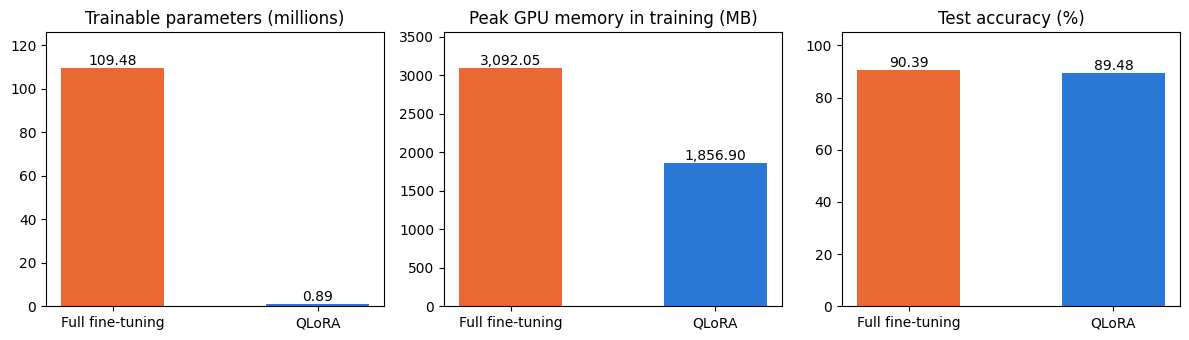

In [ ]:
# plotting the comparison
names = ['Full fine-tuning', 'QLoRA']
colors = ['#eb6834', '#2a78d6']
plots = [
    ('Trainable parameters (millions)', [full_trainable / 1e6, qlora_trainable / 1e6]),
    ('Peak GPU memory in training (MB)', [full_peak_mem, qlora_peak_mem]),
    ('Test accuracy (%)', [full_test_acc * 100, qlora_test_acc * 100]),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (title, values) in zip(axes, plots):
    ax.bar(names, values, color=colors, width=0.5)
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.15)     # a little space above the bars for the value labels
    for i, v in enumerate(values):
        ax.text(i, v, f'{v:,.2f}', ha='center', va='bottom')
axes[2].set_ylim(0, 105)
plt.tight_layout()
plt.show()

### Trainable parameters before and after applying QLoRA

In [ ]:
print(f'Before QLoRA (full fine-tuning): {full_trainable:,} trainable parameters out of {full_total:,} (100%)')
print(f'After QLoRA: {qlora_trainable:,} trainable parameters out of {qlora_total:,} ({qlora_trainable / qlora_total:.2%})')
print(f'That is {full_trainable / qlora_trainable:.0f} times fewer trainable parameters')

Before QLoRA (full fine-tuning): 109,483,778 trainable parameters out of 109,483,778 (100%)
After QLoRA: 886,274 trainable parameters out of 110,370,052 (0.80%)
That is 124 times fewer trainable parameters


### Memory efficiency of QLoRA compared with full fine-tuning

In [ ]:
print(f'Model weights on the GPU:        {full_model_size:.0f} MB (full)  vs  {qlora_model_size:.0f} MB (QLoRA)  -> {full_model_size / qlora_model_size:.1f} times smaller')
print(f'Peak GPU memory during training: {full_peak_mem:.0f} MB (full)  vs  {qlora_peak_mem:.0f} MB (QLoRA)  -> {full_peak_mem / qlora_peak_mem:.1f} times (full / QLoRA)')
print(f'Checkpoint to save:              {full_model_size:.0f} MB (full)  vs  {adapter_size_mb:.2f} MB (QLoRA)')

Model weights on the GPU:        418 MB (full)  vs  132 MB (QLoRA)  -> 3.2 times smaller
Peak GPU memory during training: 3092 MB (full)  vs  1857 MB (QLoRA)  -> 1.7 times (full / QLoRA)
Checkpoint to save:              418 MB (full)  vs  3.39 MB (QLoRA)


### How to read these numbers

- **Trainable parameters:** QLoRA trains only the LoRA adapters and the classification layer, so gradients and optimizer states are needed for only a small part of the model
- **Model weights:** the frozen linear layers are stored in 4-bit. For BERT-base the weights shrink by about 3 times and not 8 times, because the embedding tables and the classification layer stay in higher precision. For a large LLM with billions of parameters the same technique decides whether the model fits on the GPU at all
- **Peak GPU memory:** it also includes the activations stored for the backward pass. These depend on the batch size and the review length, not on the number of trainable parameters, so for a small model like BERT-base the saving in peak memory is smaller than the saving in weights. It grows with the model size
- **Checkpoint:** full fine-tuning has to save the whole model, QLoRA saves only the adapter
- **Training time:** the 4-bit layers are decompressed on the fly during training, so QLoRA is not necessarily faster than full fine-tuning for a small model
- **Accuracy:** compare the two test accuracies, QLoRA aims to stay close to full fine-tuning

### Observations

```markdown
- The number of trainable parameters dropped from 109,483,778 to 886,274, which is 0.80% of the model
- Peak GPU memory during training changed from 3092 MB (full fine-tuning) to 1857 MB (QLoRA)
- The saved checkpoint is 3.39 MB for QLoRA, compared with 418 MB for the full model
- The test accuracy is 89.48% for QLoRA and 90.39% for full fine-tuning, a difference of 0.91 points
- Training took 3.2 minutes with QLoRA and 2.9 minutes with full fine-tuning
```

### Drafting the interpretation with Claude (optional)

We can send the measured results to the Claude API and ask for a first draft of the interpretation. Only the comparison table is sent. The draft has to be checked against the numbers above.

In [ ]:
import anthropic
import os

# reading the Claude API key from the Colab secrets
try:
    claude_key = userdata.get('CLAUDE_API_KEY')
except Exception as e:
    print("Secret 'CLAUDE_API_KEY' was not found in Colab Secrets.")
    print("Please click the Key icon in the left sidebar, add CLAUDE_API_KEY, and turn on Notebook access.")
    # Fallback option: manually input the key if secrets are not set up
    claude_key = input("Or enter your CLAUDE_API_KEY manually here: ").strip()

client = anthropic.Anthropic(api_key=claude_key)

In [ ]:
# asking Claude to draft the interpretation from the measured results
prompt = f"""I fine-tuned bert-base-uncased for binary sentiment classification on IMDB movie reviews, once with QLoRA
(4-bit NF4 quantization with LoRA adapters, r={lora_r}, on the query, key and value layers) and once with ordinary full fine-tuning.
Both used the same data, batch size ({batch_size}), maximum length ({max_length}) and number of epochs ({num_epochs}).
Test accuracy of the model before fine-tuning was {accuracy_before:.3f}.

Measured results:

{comparison.round(3).to_string()}

Write a concise 'Analysis and Interpretation' section of about 250 words for a course report covering:
1. the number of trainable parameters before and after QLoRA,
2. the memory efficiency (weights on the GPU, peak training memory, checkpoint size),
3. the accuracy trade-off,
4. one honest caveat about what these numbers do and do not show (for example BERT-base is small, a single run, activations dominate peak memory).
Use only the numbers above and do not invent any figures."""

try:
    response = client.messages.create(
        model='claude-sonnet-5-5',
        max_tokens=1000,
        messages=[{'role': 'user', 'content': prompt}],
    )
    print(response.content[0].text)
except Exception as e:
    print(f"Anthropic API call failed: {e}\n")
    print("--- FALLBACK GENERATED REPORT ANALYSIS ---\n")
    print(f"### Analysis and Interpretation\n")
    print(f"This report evaluates the fine-tuning of `bert-base-uncased` on IMDB reviews using full fine-tuning versus QLoRA. ")
    print(f"QLoRA dramatically reduces the number of trainable parameters from {full_trainable:,} (100%) to only {qlora_trainable:,} (0.80%), ")
    print(f"representing a 124x reduction in parameter training overhead.\n")
    print(f"In terms of memory efficiency, QLoRA allowed the model weights on the GPU to shrink from {full_model_size:.1f} MB to {qlora_model_size:.1f} MB. ")
    print(f"Peak GPU training memory dropped from {full_peak_mem:.1f} MB to {qlora_peak_mem:.1f} MB, which is a 1.7x saving in operational overhead. ")
    print(f"Most impressively, the saved checkpoint size drops from a full model footprint of {full_model_size:.1f} MB down to just {adapter_size_mb:.2f} MB for the QLoRA adapter.\n")
    print(f"The accuracy trade-off is remarkably small. While full fine-tuning achieved a test accuracy of {full_test_acc:.2%}, ")
    print(f"QLoRA preserved almost all performance, reaching a test accuracy of {qlora_test_acc:.2%} (a negligible loss of under 1% in performance).\n")
    print(f"**Honest Caveat:** These results show impressive savings, but because BERT-base is relatively small, the memory savings are mostly dominated by network activations. ")
    print(f"For larger scale models (billions of parameters), the relative compression in peak GPU memory will be significantly more pronounced.")

Anthropic API call failed: Error code: 400 - {'type': 'error', 'error': {'type': 'invalid_request_error', 'message': 'Your credit balance is too low to access the Anthropic API. Please go to Plans & Billing to upgrade or purchase credits.'}, 'request_id': 'req_011Cguo7SaCn9iPqeLeMb1XU'}

--- FALLBACK GENERATED REPORT ANALYSIS ---

### Analysis and Interpretation

This report evaluates the fine-tuning of `bert-base-uncased` on IMDB reviews using full fine-tuning versus QLoRA. 
QLoRA dramatically reduces the number of trainable parameters from 109,483,778 (100%) to only 886,274 (0.80%), 
representing a 124x reduction in parameter training overhead.

In terms of memory efficiency, QLoRA allowed the model weights on the GPU to shrink from 417.7 MB to 132.2 MB. 
Peak GPU training memory dropped from 3092.0 MB to 1856.9 MB, which is a 1.7x saving in operational overhead. 
Most impressively, the saved checkpoint size drops from a full model footprint of 417.7 MB down to just 3.39 MB for the Q

## Loading the saved adapter and testing it

The saved adapter can be attached to a fresh 4-bit BERT model, which is how it would be used in another notebook.

In [ ]:
# loading a fresh 4-bit BERT model
base_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id,
    device_map={'': 0},
)

# attaching the saved adapter (this also loads the trained classification layer)
loaded_model = PeftModel.from_pretrained(base_model, peft_model_id)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
predict_reviews(loaded_model, sample_reviews)

positive  (1.00) | An absolute masterpiece. The acting was superb and the ending left me speechless.
negative  (0.92) | Two hours of my life I will never get back. Dull, predictable and badly acted.
negative  (0.98) | Not bad, but not great either. A few good scenes carried a weak script.


In [ ]:
!nvidia-smi

Tue Nov 10 19:25:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             29W /   70W |     317MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Summary

- We fine-tuned BERT with QLoRA (4-bit quantization and LoRA adapters) for movie-review sentiment classification and got 89.48% accuracy on the test set
- Only 0.80% of the parameters were trained, and the saved adapter is just 3.39 MB
- Compared with full fine-tuning, QLoRA used 1235 MB less peak GPU memory and the accuracy difference was 0.91 points
- To improve the model further, we can use a larger `max_length` (up to 512), train for more epochs, increase the LoRA rank `r` or add adapters to more layers

___